In [1]:
# =====================================
# HMM CNN EXPERIMENT
# =====================================

import pandas as pd
import matplotlib.pyplot as plt
import torch

from src.run.model.run_fully_hmm_cnn_classifier import RunFullyHmmCnnClassifier
from src.run.preprocess.config import _project_path


Paziente 00003 | segmenti N=50 (task [1, 8])
label vera     : Parkinson
logit medi     : [-0.2188  0.5584]  ->  decisione: Parkinson  (corretta)
classe spiegata: Parkinson


<Figure size 640x480 with 0 Axes>

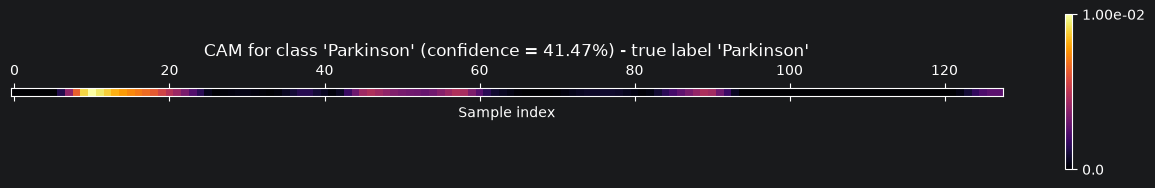

<Figure size 640x480 with 0 Axes>

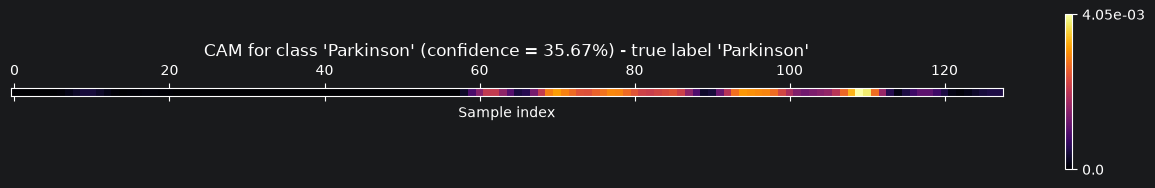

<Figure size 640x480 with 0 Axes>

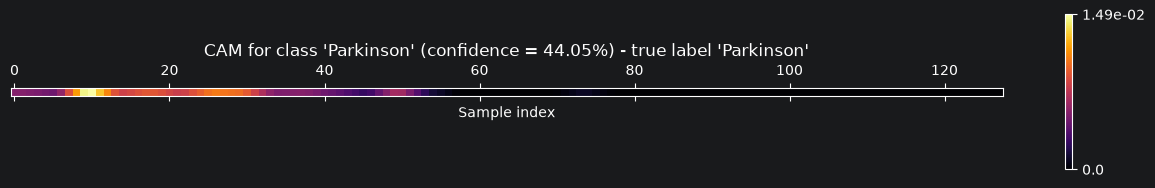

<Figure size 640x480 with 0 Axes>

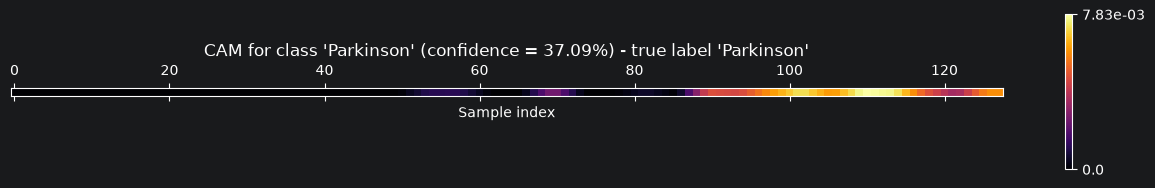

<Figure size 640x480 with 0 Axes>

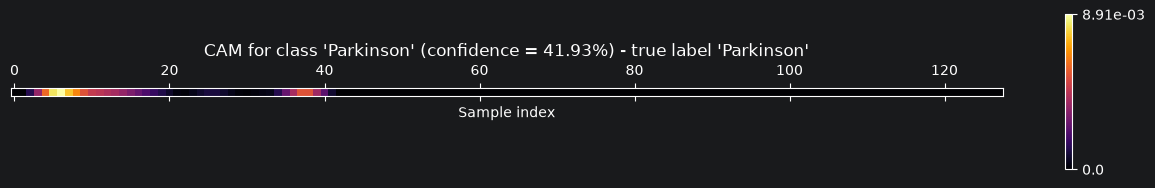

<Figure size 640x480 with 0 Axes>

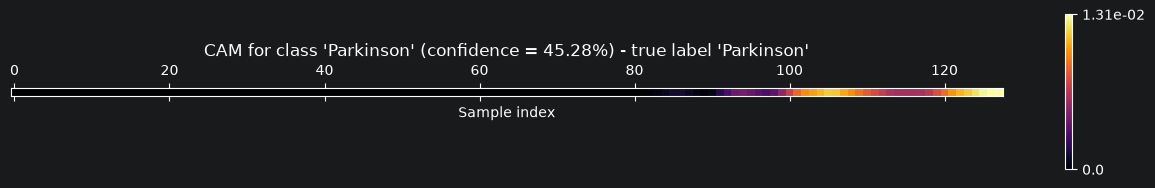

<Figure size 640x480 with 0 Axes>

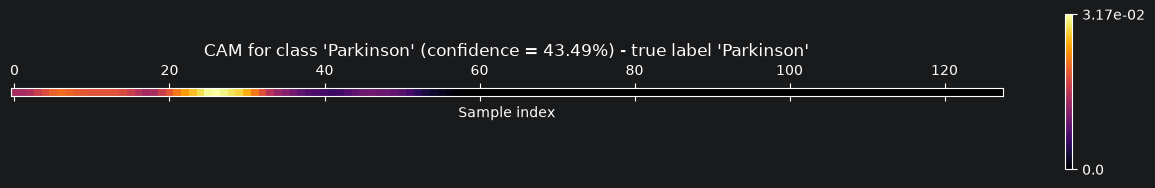

<Figure size 640x480 with 0 Axes>

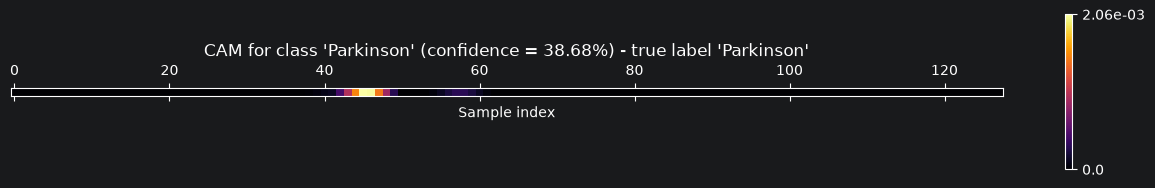

<Figure size 640x480 with 0 Axes>

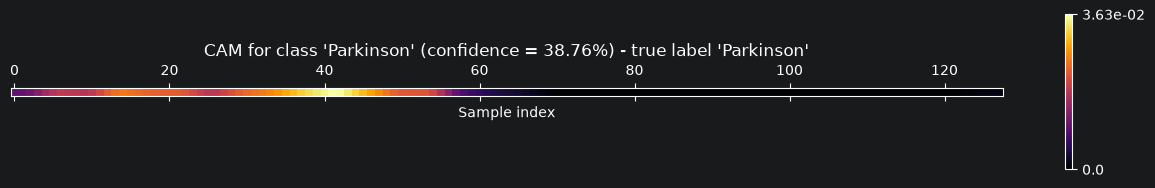

<Figure size 640x480 with 0 Axes>

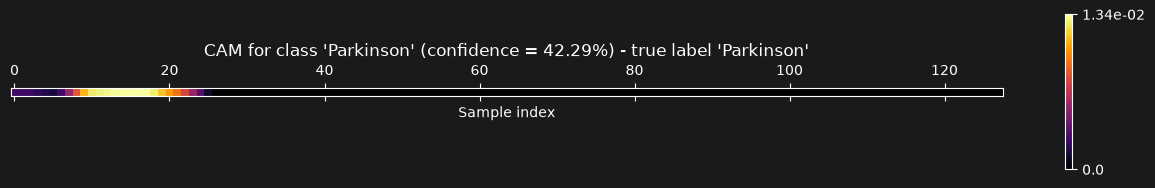

<Figure size 640x480 with 0 Axes>

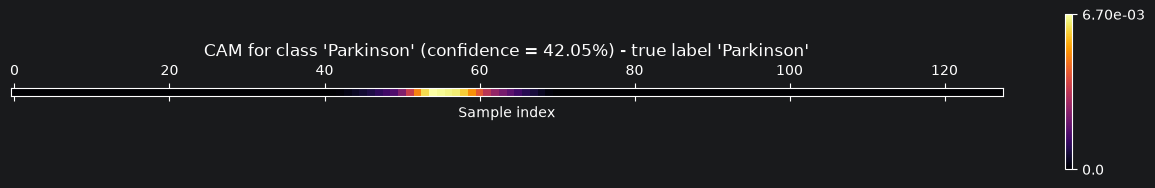

<Figure size 640x480 with 0 Axes>

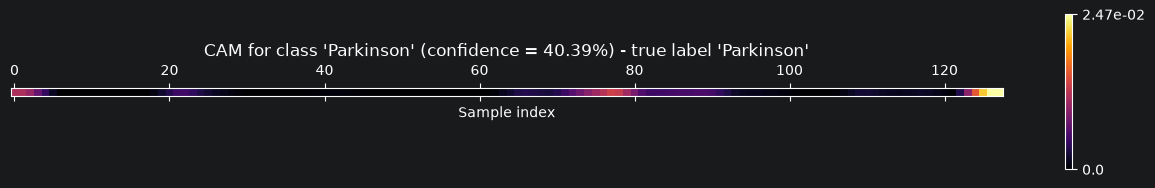

<Figure size 640x480 with 0 Axes>

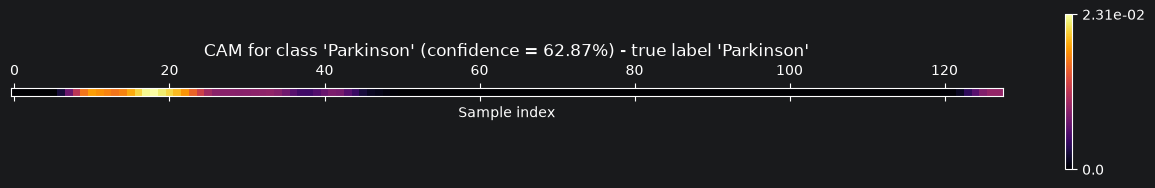

<Figure size 640x480 with 0 Axes>

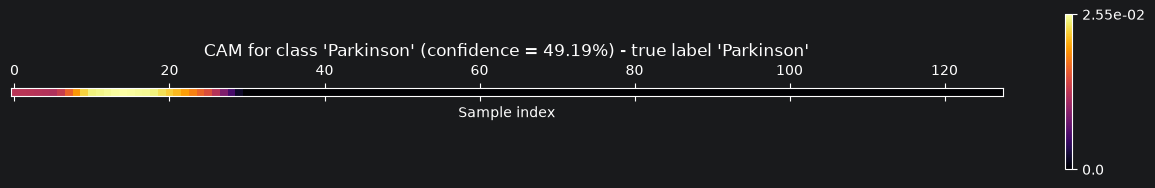

<Figure size 640x480 with 0 Axes>

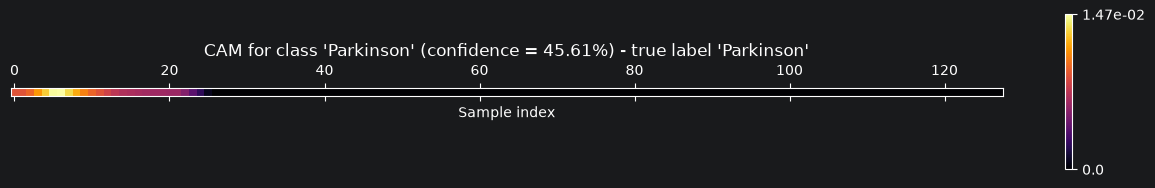

<Figure size 640x480 with 0 Axes>

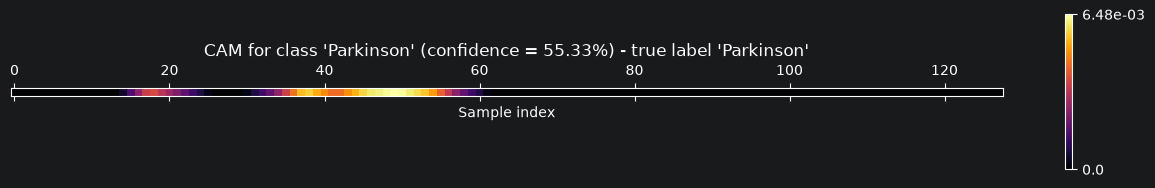

<Figure size 640x480 with 0 Axes>

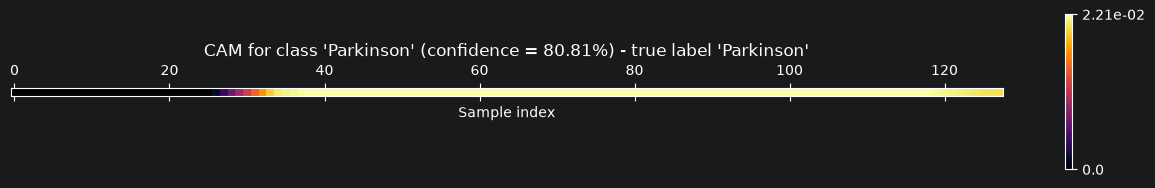

<Figure size 640x480 with 0 Axes>

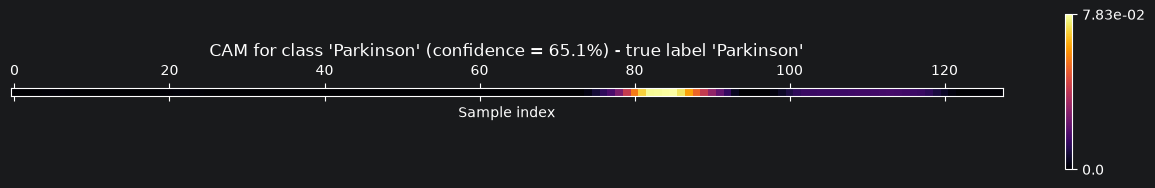

<Figure size 640x480 with 0 Axes>

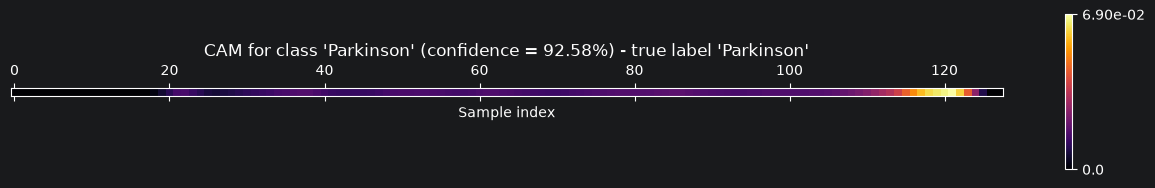

<Figure size 640x480 with 0 Axes>

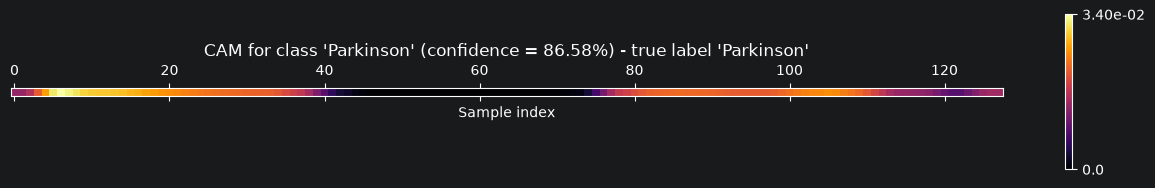

<Figure size 640x480 with 0 Axes>

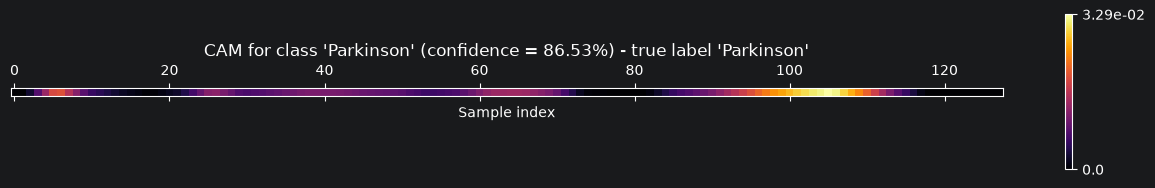

<Figure size 640x480 with 0 Axes>

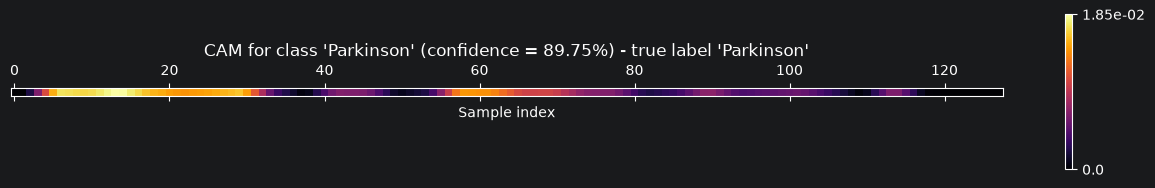

<Figure size 640x480 with 0 Axes>

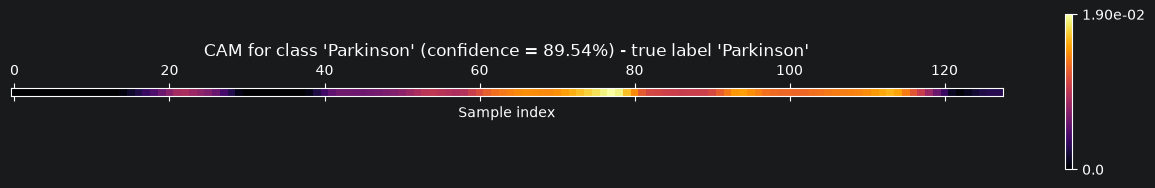

<Figure size 640x480 with 0 Axes>

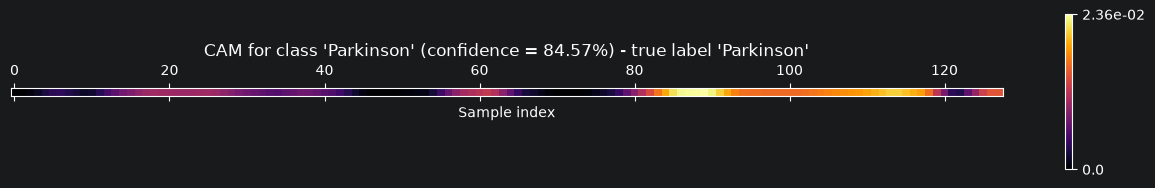

<Figure size 640x480 with 0 Axes>

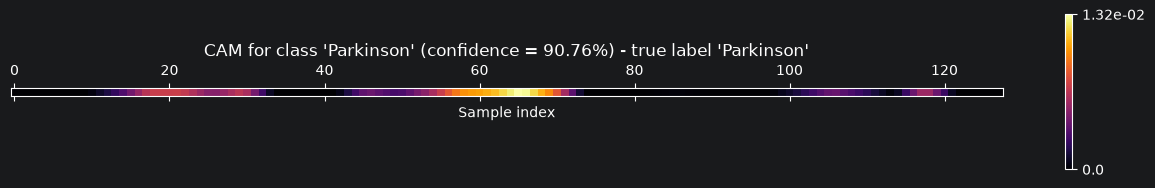

<Figure size 640x480 with 0 Axes>

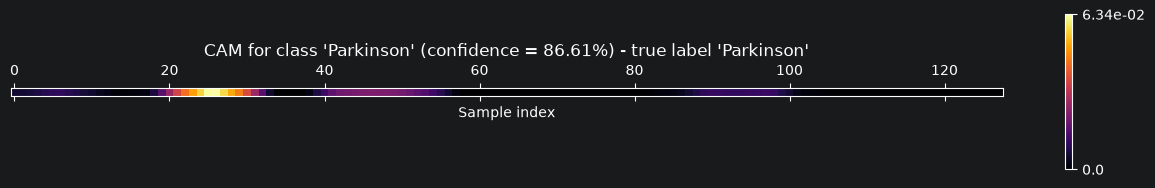

<Figure size 640x480 with 0 Axes>

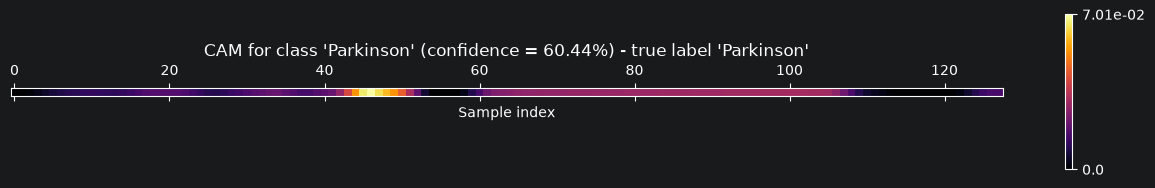

<Figure size 640x480 with 0 Axes>

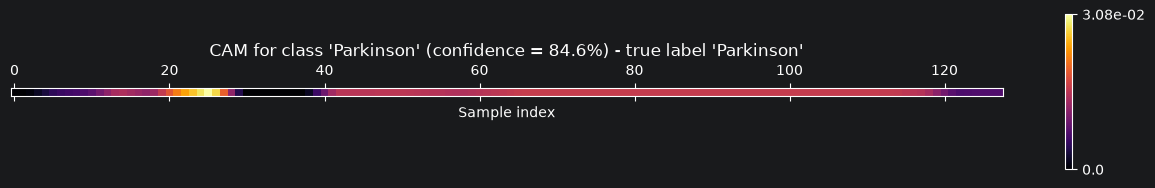

<Figure size 640x480 with 0 Axes>

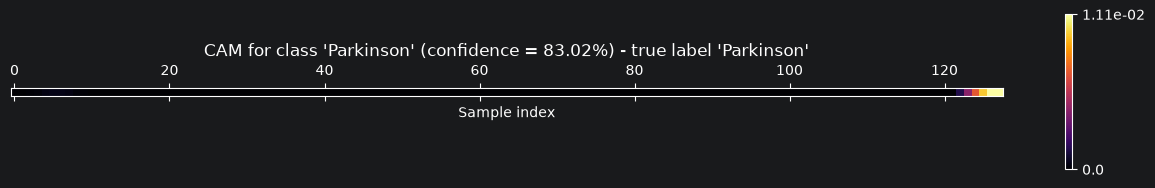

<Figure size 640x480 with 0 Axes>

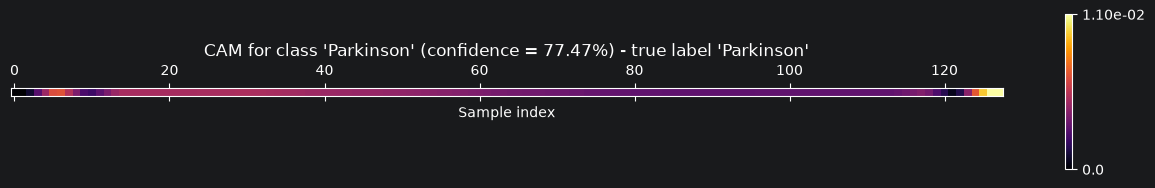

<Figure size 640x480 with 0 Axes>

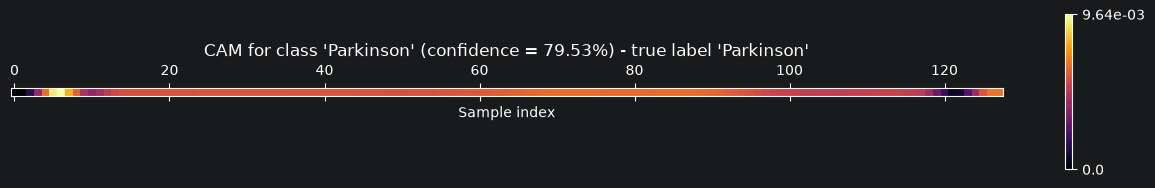

<Figure size 640x480 with 0 Axes>

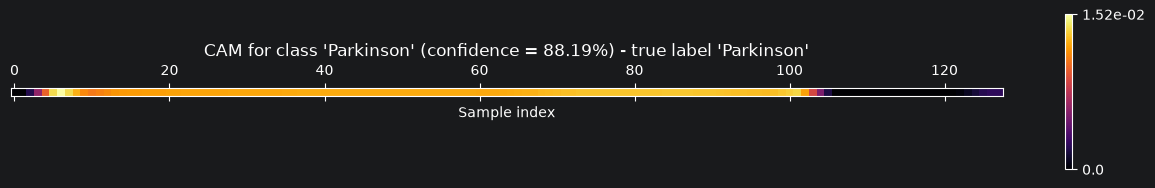

<Figure size 640x480 with 0 Axes>

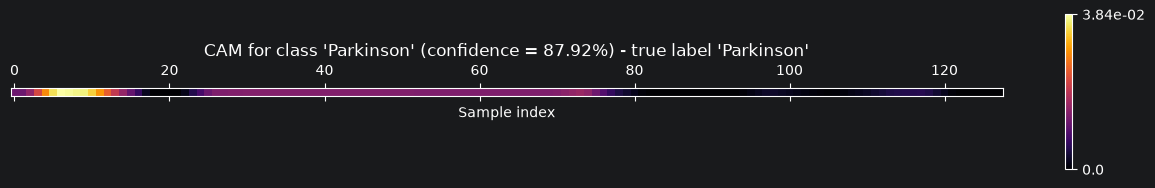

<Figure size 640x480 with 0 Axes>

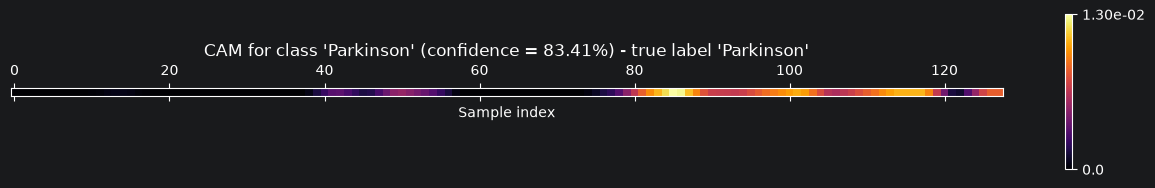

<Figure size 640x480 with 0 Axes>

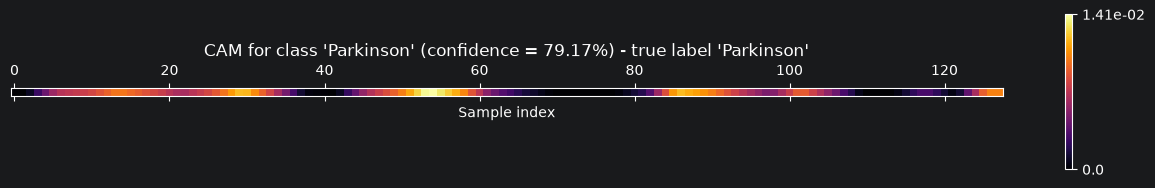

<Figure size 640x480 with 0 Axes>

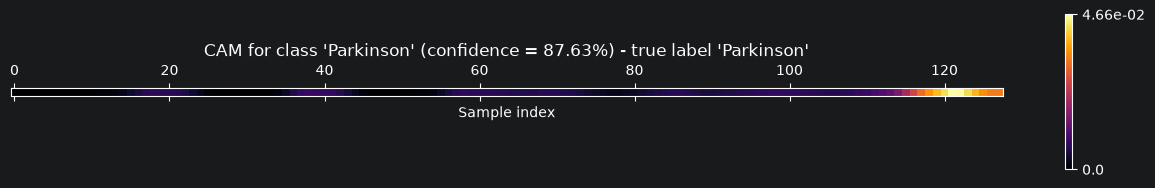

<Figure size 640x480 with 0 Axes>

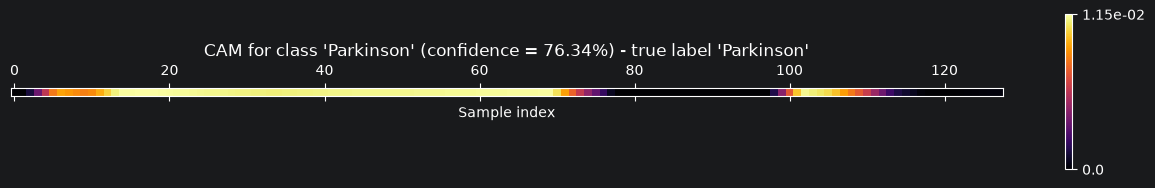

<Figure size 640x480 with 0 Axes>

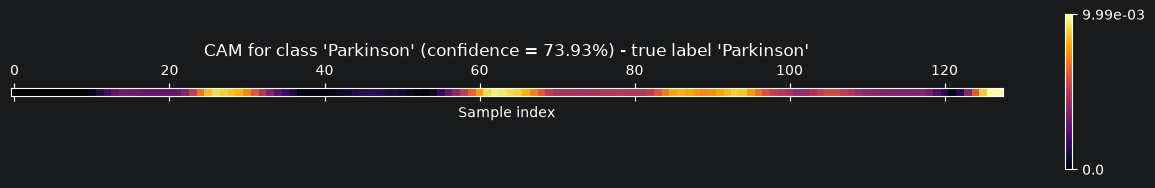

<Figure size 640x480 with 0 Axes>

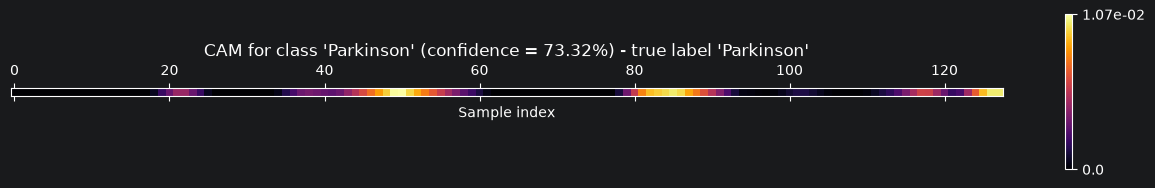

<Figure size 640x480 with 0 Axes>

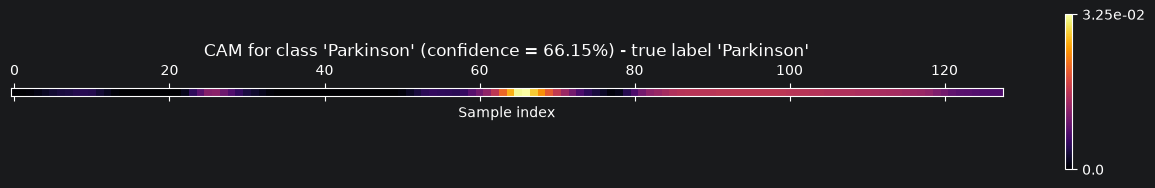

<Figure size 640x480 with 0 Axes>

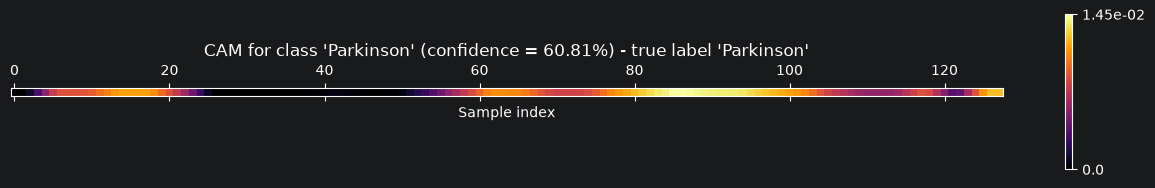

<Figure size 640x480 with 0 Axes>

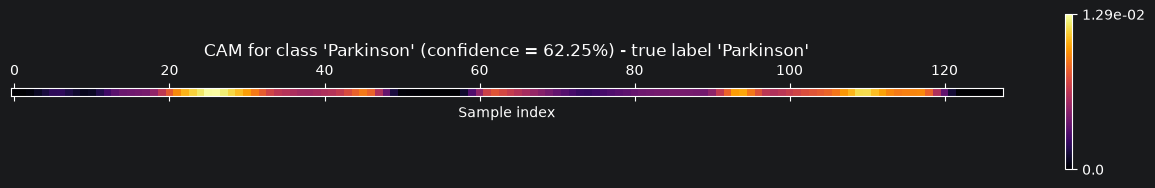

<Figure size 640x480 with 0 Axes>

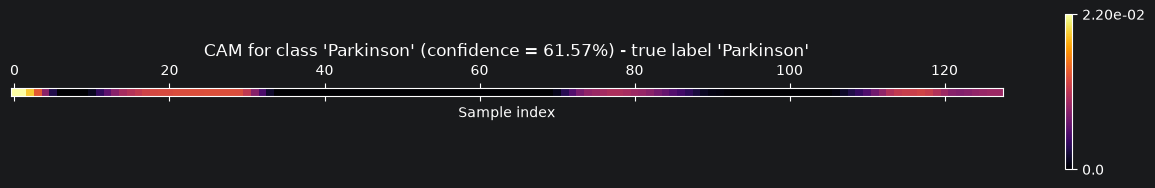

<Figure size 640x480 with 0 Axes>

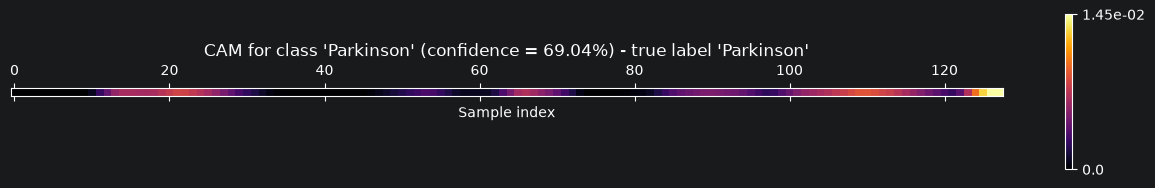

<Figure size 640x480 with 0 Axes>

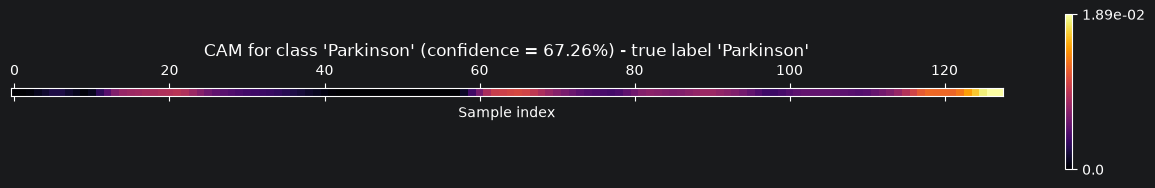

<Figure size 640x480 with 0 Axes>

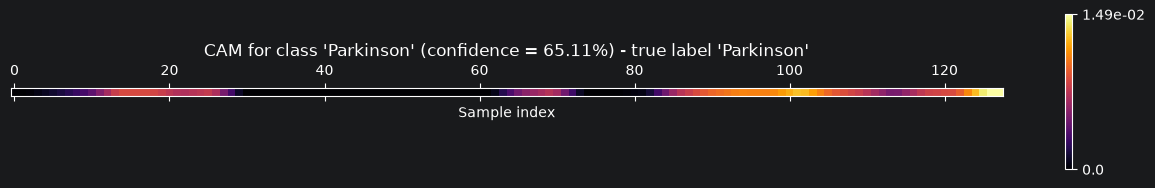

<Figure size 640x480 with 0 Axes>

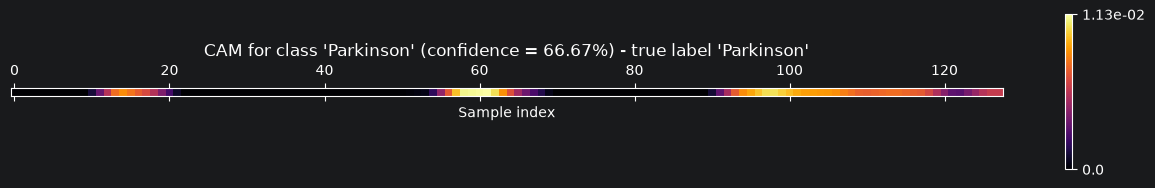

<Figure size 640x480 with 0 Axes>

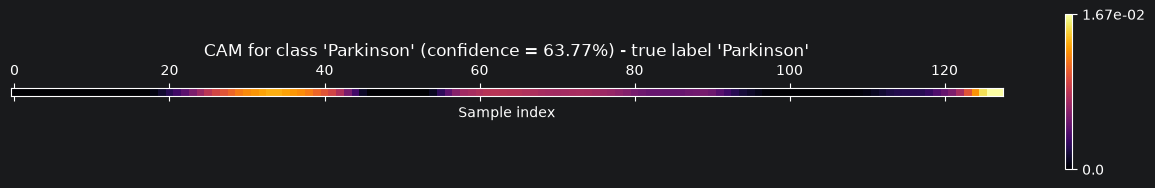

<Figure size 640x480 with 0 Axes>

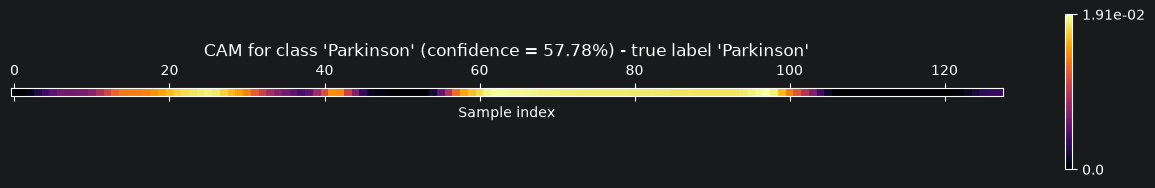

<Figure size 640x480 with 0 Axes>

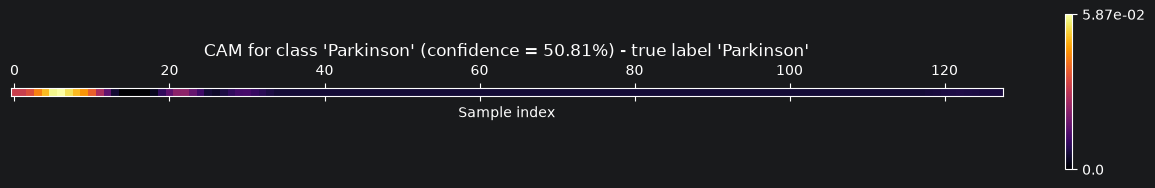

 task  state  valid  logit_0  logit_1  contrib_margin  cam_max
    1      0    128   0.2213  -0.1235         -0.0069   0.1247
    1      0    128   0.3922  -0.1976         -0.0118   0.0478
    1      0    128   0.1237  -0.1155         -0.0048   0.1791
    1      0    128   0.3110  -0.2175         -0.0106   0.1000
    1      0    128   0.2544  -0.0711         -0.0065   0.1070
    1      0    128   0.1073  -0.0821         -0.0038   0.1681
    1      0    128   0.1993  -0.0627         -0.0052   0.3989
    1      0    128   0.3335  -0.1272         -0.0092   0.0233
    1      0    128   0.1960  -0.2614         -0.0091   0.4580
    1      0    128   0.2799  -0.0308         -0.0062   0.1718
    1      0    128   0.2776  -0.0433         -0.0064   0.0852
    1      0    128   0.1130  -0.2762         -0.0078   0.3161
    1      0    128  -0.1008   0.4259          0.0105   0.2893
    1      0    128   0.1048   0.0725         -0.0006   0.3254
    1      0    128   0.2037   0.0275         -0.0035  

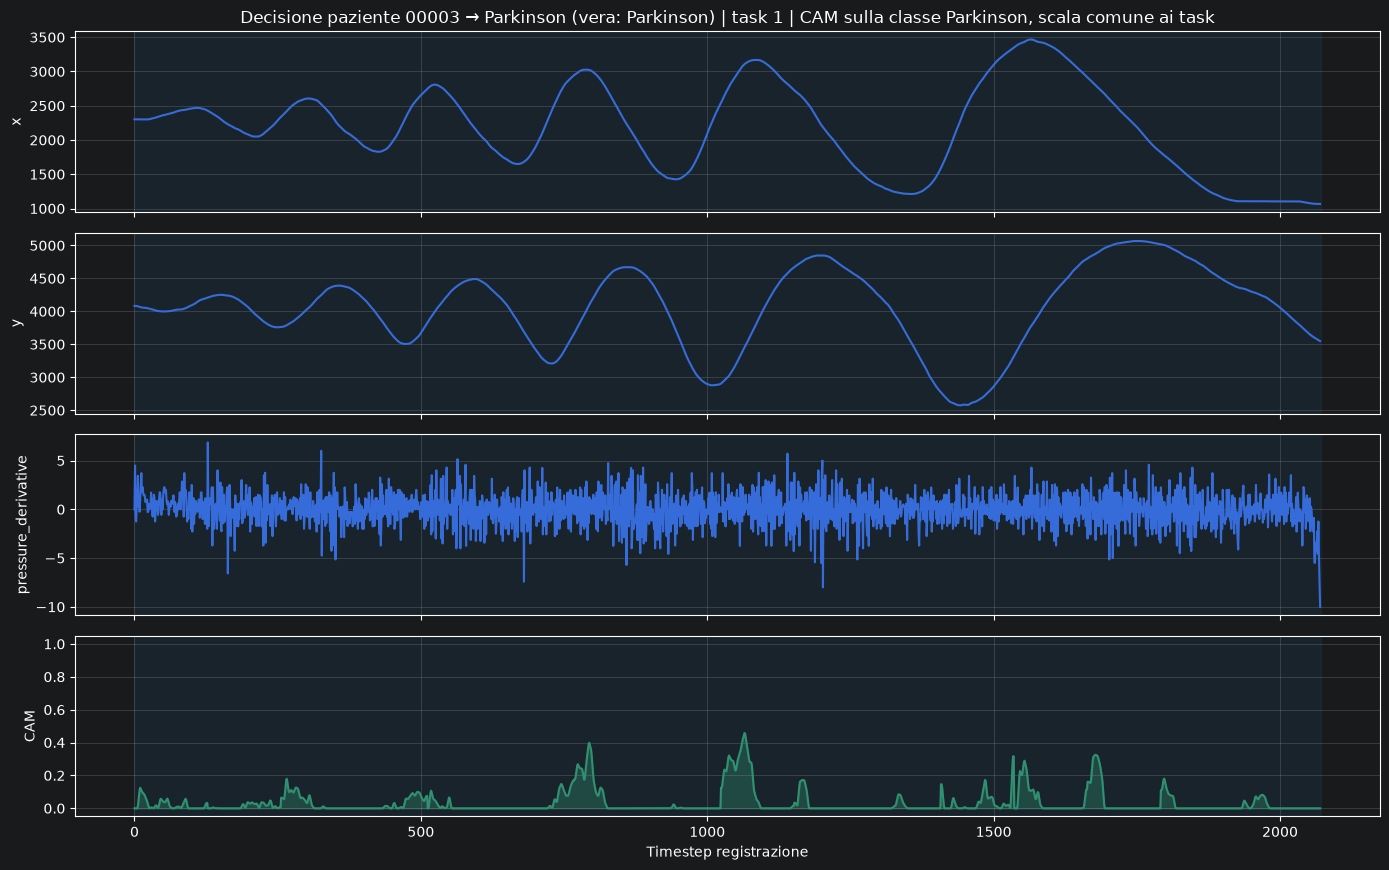

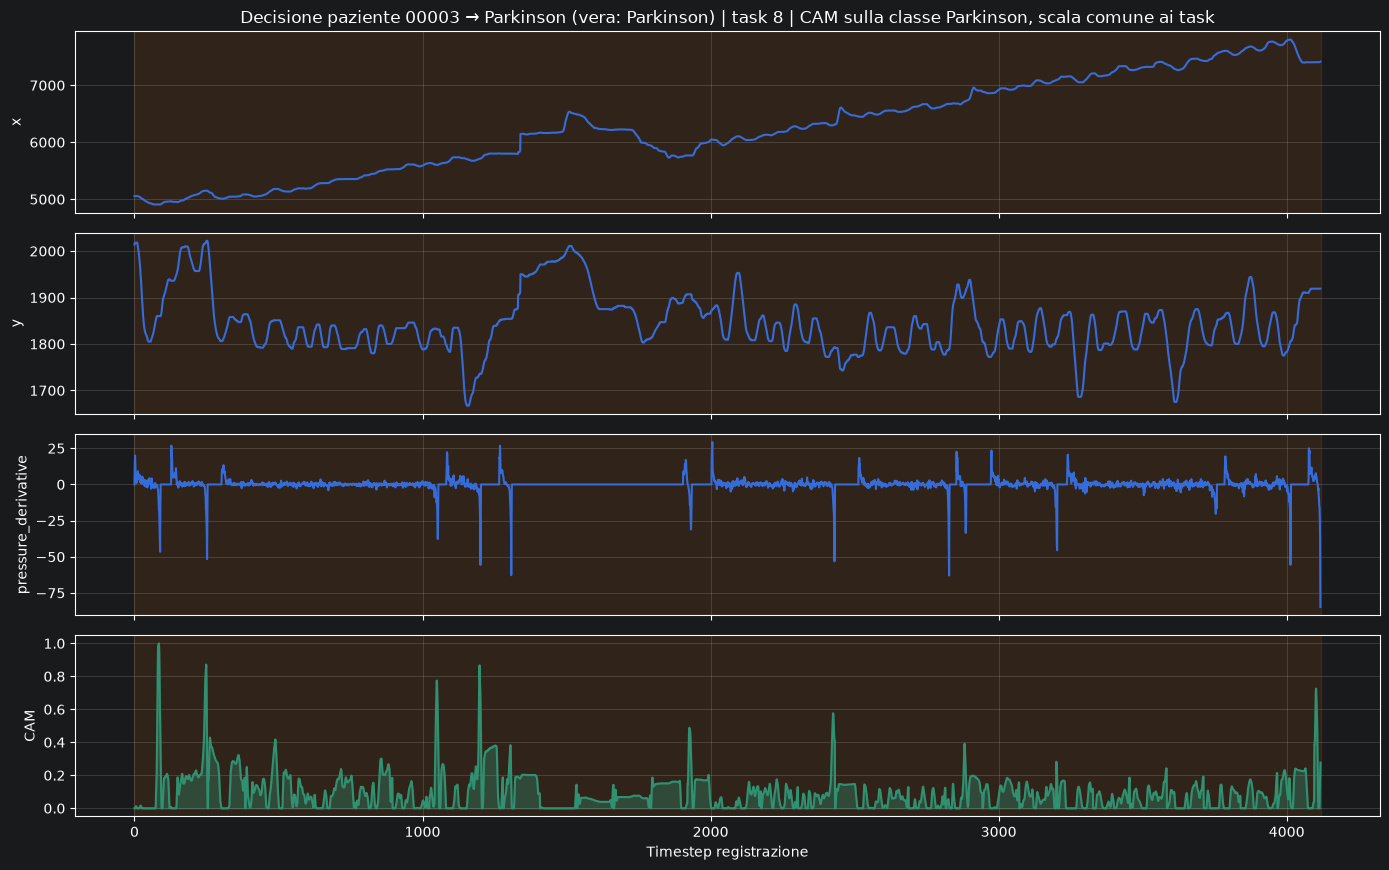

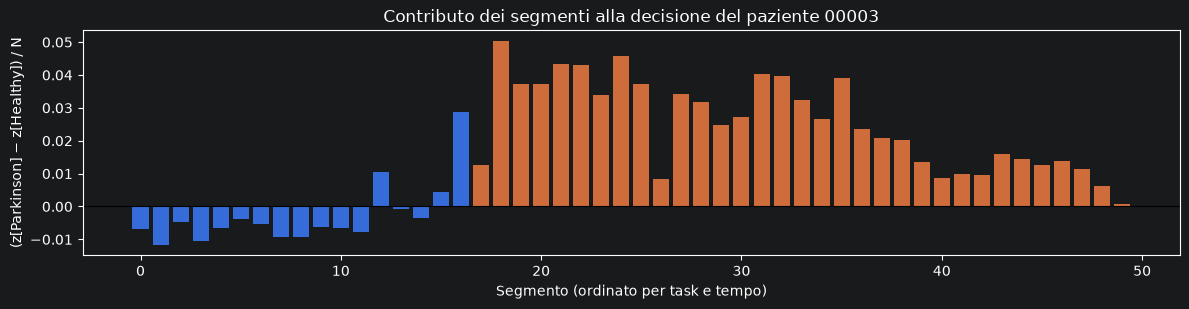

In [12]:
# =====================================
# CAM SULLA DECISIONE DEL PAZIENTE (aggregazione dei segmenti)
# Richiede aver eseguito la cella Grad-CAM precedente (model, cam_builder, ecc.)
# =====================================

def _clear_cam_hooks():
    # la libreria non rimuove i suoi hook: li svuoto prima di ogni forward/get_cam
    dict(model.named_modules())[TARGET_LAYER]._forward_hooks.clear()


def explain_decision(patient_id, target_class=None):
    if runner.aggregation not in ("mean", "average"):
        raise NotImplementedError(
            f"aggregation='{runner.aggregation}': la CAM della decisione è implementata solo per la media "
            "(con la mediana il gradiente non è lineare nei segmenti)."
        )

    idxs = [i for i in range(len(val_ds_raw)) if str(val_ds_raw[i]["patient_id"]) == str(patient_id)]
    if not idxs:
        raise RuntimeError(f"Paziente {patient_id} non presente nel fold {FOLD}.")
    idxs.sort(key=lambda i: (int(val_ds_raw[i]["task_id"]), int(val_ds_raw[i]["start"])))
    label = int(val_ds_raw[idxs[0]]["label"])

    # ---- 1) logit per segmento, aggregazione e decisione (come _evaluate_patient) ----
    segs = []
    for i in idxs:
        s = val_ds_raw[i]
        mask = s["mask"].bool()
        seg_raw = s["segment"].float()
        seg = ((seg_raw - mean) / std) * mask.unsqueeze(-1)

        _clear_cam_hooks()
        with torch.no_grad():
            z = model(seg.unsqueeze(0).to(runner.device), mask=mask.unsqueeze(0).to(runner.device))
            if isinstance(z, tuple):
                z = z[0]

        segs.append(dict(i=i, task=int(s["task_id"]), state=int(s["state"]), mask=mask,
                         valid=int(mask.sum()), seg_raw=seg_raw, seg=seg, z=z[0].cpu().numpy()))

    Z = np.stack([d["z"] for d in segs])              # [N, 2]
    N = len(Z)
    patient_logits = Z.mean(axis=0)
    pred = int(patient_logits.argmax())
    cls = pred if target_class is None else int(target_class)
    other = 1 - cls
    tasks_present = sorted({d["task"] for d in segs})

    print(f"\nPaziente {patient_id} | segmenti N={N} (task {tasks_present})")
    print(f"label vera     : {class_names[label]}")
    print(f"logit medi     : {np.round(patient_logits, 4)}  ->  decisione: {class_names[pred]}"
          f"  ({'corretta' if pred == label else 'ERRATA'})")
    print(f"classe spiegata: {class_names[cls]}")

    # ---- 2) CAM per segmento sulla classe scelta, in scala grezza comune ----
    for d in segs:
        _clear_cam_hooks()
        cam_dict, probs_dict, ranges_dict = cam_builder.get_cam(
            data_list=[d["seg"].numpy()],
            data_labels=[label],
            target_classes=[cls],
            explainer_types="Grad-CAM",
            target_layers=TARGET_LAYER,
            softmax_final=False,
            extra_inputs_list=[d["mask"].unsqueeze(0).to(runner.device)],
        )
        key = f"Grad-CAM_{TARGET_LAYER}_class{cls}"
        cam01 = np.asarray(cam_dict[key][0], dtype=np.float32).squeeze() / 255.0
        raw_max = float(np.ravel(ranges_dict[key][1])[0])
        d["cam"] = (cam01 * raw_max / N)[: d["valid"]]                   # peso 1/N: contributo alla media
        d["contrib_logit"] = float(d["z"][cls] / N)                      # contributo al logit medio
        d["contrib_margin"] = float((d["z"][cls] - d["z"][other]) / N)   # contributo al margine decisionale

    gmax = max(float(d["cam"].max()) for d in segs)
    for d in segs:
        d["cam_n"] = d["cam"] / gmax if gmax > 0 else d["cam"]          # normalizzazione globale sul paziente

    table = pd.DataFrame([{
        "task": d["task"], "state": d["state"], "valid": d["valid"],
        "logit_0": d["z"][0], "logit_1": d["z"][1],
        "contrib_margin": d["contrib_margin"], "cam_max": float(d["cam_n"].max()),
    } for d in segs])
    print(table.round(4).to_string(index=False))
    print("Somma contributi al margine:", round(float(table["contrib_margin"].sum()), 4),
          f"(>0 => decisione per {class_names[cls]})")

    # ---- 3) un grafico per task: segnale + CAM della decisione ----
    cmap = plt.get_cmap("tab10")
    n_features = segs[0]["seg_raw"].shape[1]
    for task in tasks_present:
        ds = [d for d in segs if d["task"] == task]
        signal = np.concatenate([d["seg_raw"][: d["valid"]].numpy() for d in ds], axis=0)
        cam = np.concatenate([d["cam_n"] for d in ds])
        states = np.concatenate([np.full(d["valid"], d["state"]) for d in ds])
        t = np.arange(len(cam))

        fig, axes = plt.subplots(n_features + 1, 1, figsize=(14, 2.2 * (n_features + 1)), sharex=True)
        for a in axes:
            start = 0
            for k in range(1, len(states) + 1):
                if k == len(states) or states[k] != states[start]:
                    a.axvspan(start, k, color=cmap(int(states[start])), alpha=0.10)
                    start = k
        for j in range(n_features):
            axes[j].plot(t, signal[:, j], color="C0")
            axes[j].set_ylabel(feature_names_plot[j])
            axes[j].grid(True, alpha=0.3)
        axes[0].set_title(f"Decisione paziente {patient_id} → {class_names[pred]} (vera: {class_names[label]}) | "
                          f"task {task} | CAM sulla classe {class_names[cls]}, scala comune ai task")
        axes[-1].plot(t, cam, color="C3", linewidth=1.5)
        axes[-1].fill_between(t, 0, cam, color="C3", alpha=0.35)
        axes[-1].set_ylabel("CAM")
        axes[-1].set_xlabel("Timestep registrazione")
        axes[-1].set_ylim(-0.05, 1.05)
        axes[-1].grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

    # ---- 4) contributo di ogni segmento alla decisione ----
    colors = [("C0" if d["task"] == tasks_present[0] else "C1") for d in segs]
    plt.figure(figsize=(12, 3.2))
    plt.bar(np.arange(N), [d["contrib_margin"] for d in segs], color=colors)
    plt.axhline(0, color="k", linewidth=0.8)
    plt.xlabel("Segmento (ordinato per task e tempo)")
    plt.ylabel(f"(z[{class_names[cls]}] − z[{class_names[other]}]) / N")
    plt.title(f"Contributo dei segmenti alla decisione del paziente {patient_id}")
    plt.tight_layout()
    plt.show()

    return segs, table


# --- esegui su un paziente del fold di validazione ---
patients_in_fold = sorted({pid for pid, _ in available})
PATIENT_ID = patients_in_fold[0]               # cambia indice per un altro paziente
segs, table = explain_decision(PATIENT_ID)     # target_class=None: spiega la classe decisa